# Telco Customer Churn: risk ranking and decision thresholds

**Question:** Can customer services, billing, and tenure distinguish churned
customers from those who stayed, and how does a threshold affect mistakes?

This is a retrospective classification case study on the supplied IBM-style
Telco sample. It is not a prospective next-month forecast: the file has no
snapshot dates, observation windows, or intervention outcomes.

We compare eight algorithms and a prior baseline. Average precision (AP)
is the primary model-selection metric because churn is the minority class.
AP summarizes precision across recall increments; it is not trapezoidal
area under a precision–recall curve. Accuracy alone can reward predicting
that everyone stays.

**Predeclared checks**
1. Does gradient boosting outperform logistic regression in test AP?
2. Does validation-selected F1 thresholding improve the selected model's
   test F1 over 0.50?

Paired customer bootstrap intervals will report support or inconclusiveness,
not guarantee either hypothesis. No test-driven model or threshold changes.

In [1]:
import hashlib
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate

from src.modeling import (
    ALGORITHMS,
    CATEGORICAL,
    FEATURES,
    NUMERIC,
    SEED,
    bootstrap_difference,
    make_models,
    read_data,
    scores,
    split_data,
    threshold_table,
)
from src.plots import (
    cohort_plot,
    comparison_plot,
    cost_plot,
    diagnostic_plots,
    importance_plot,
    save_figure,
    threshold_plot,
)

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    raise RuntimeError("Run the notebook from the project folder.")
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
for directory in [REPORTS, FIGURES, ROOT / "models"]:
    directory.mkdir(exist_ok=True)
DATA_PATH = ROOT / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
pd.options.display.float_format = "{:.4f}".format


## 1. Inspect the data before modeling

Customer ID is excluded from every model. Blank total charges become
missing numeric values. Median imputation and its missingness indicator
are learned on training rows only. Other columns keep their original
categories, including service-not-applicable categories.

The source file is never rewritten. See `DATASET.md` for attribution and
the difference between a public sample and real operational data.

In [2]:
data = read_data(DATA_PATH)
audit = {
    "rows": len(data),
    "columns": len(data.columns),
    "churn_count": int(data.Churn.eq("Yes").sum()),
    "churn_rate": float(data.Churn.eq("Yes").mean()),
    "missing_total_charges": int(data.TotalCharges.isna().sum()),
    "duplicate_customer_ids": int(data.customerID.duplicated().sum()),
    "sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
}
display(pd.Series(audit, name="Dataset audit"))
display(data.drop(columns="customerID").head())
print("Blank total charges by tenure:")
display(data.loc[data.TotalCharges.isna(), "tenure"].value_counts())


rows                                                                   7043
columns                                                                  21
churn_count                                                            1869
churn_rate                                                           0.2654
missing_total_charges                                                    11
duplicate_customer_ids                                                    0
sha256                    88be4b93fbe0cc83421af1c503794c97c342eca914c157...
Name: Dataset audit, dtype: object

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.8500,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5000,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.1500,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.7500,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.6500,Yes


Blank total charges by tenure:


tenure
0    11
Name: count, dtype: int64

## 2. Freeze train, validation, and test partitions

Stratified 60/20/20 customer split, seed 42. IDs are unique; each customer
appears in exactly one partition. This measures generalization to randomly
held-out sample customers, not to a later time period or a new company.

Preprocessing is inside each pipeline. Three-fold cross-validation uses
only training data. Hyperparameters are fixed in `src/modeling.py`; there
is no search across test results and no oversampling before splitting.

In [3]:
train, validation, test = split_data(data)
parts = {"train": train, "validation": validation, "test": test}
manifest = pd.concat(
    [
        part[["customerID", "Churn"]].assign(split=name)
        for name, part in parts.items()
    ]
)
manifest.to_csv(REPORTS / "split_manifest.csv", index=False)
assert manifest.customerID.is_unique
assert len(manifest) == len(data)
split_summary = pd.DataFrame(
    [
        {
            "split": name,
            "customers": len(part),
            "churn_rate": part.Churn.eq("Yes").mean(),
        }
        for name, part in parts.items()
    ]
)
display(split_summary)
x_train, y_train = train[FEATURES], train.Churn.eq("Yes").astype(int)
x_valid = validation[FEATURES]
y_valid = validation.Churn.eq("Yes").astype(int)
x_test, y_test = test[FEATURES], test.Churn.eq("Yes").astype(int)


,split,customers,churn_rate
0,train,4225,0.2653
1,validation,1409,0.2654
2,test,1409,0.2654


## 3. Algorithms and training-only cross-validation

Logistic regression is the interpretable linear baseline. Trees and
ensembles learn nonlinear interactions; KNN uses distance; SVM uses an
RBF margin; Gaussian Naive Bayes makes strong conditional-independence and
Gaussian assumptions, including for encoded categories.

The PyTorch MLP uses 32 and 16 hidden units, ReLU, 15% dropout, Adam,
weight decay 0.001, and binary cross-entropy on logits. It finds its epoch
count using an internal 15% stopping partition with its own fitted
preprocessor, then refits on all supplied training rows for that many
epochs. It runs on CPU for portability. This small dataset does not need
CUDA. Random seeds and CPU deterministic operations are fixed.

In [4]:
models = make_models()
display(
    pd.DataFrame(ALGORITHMS.items(), columns=["Algorithm", "How it works"])
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_rows = []
for name, model in models.items():
    print("Cross-validation:", name, flush=True)
    result = cross_validate(
        model,
        x_train,
        y_train,
        cv=cv,
        n_jobs=1,
        scoring={"AP": "average_precision", "ROC_AUC": "roc_auc"},
        error_score="raise",
    )
    for fold in range(3):
        cv_rows.append(
            {
                "model": name,
                "fold": fold + 1,
                "AP": result["test_AP"][fold],
                "ROC_AUC": result["test_ROC_AUC"][fold],
            }
        )
cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(REPORTS / "cross_validation.csv", index=False)
display(cv_results.groupby("model")[["AP", "ROC_AUC"]].agg(["mean", "std"]))


,Algorithm,How it works
0,Prior baseline,Predicts the training churn prevalence for eve...
1,Logistic regression,A linear combination of features becomes a pro...
2,Decision tree,A sequence of learned feature splits separates...
3,Random forest,Averages many trees trained on bootstrap samples.
4,Gradient boosting,Adds small trees that correct the current pred...
5,Gaussian Naive Bayes,Combines class-conditional feature densities u...
6,K-nearest neighbors,Uses the outcomes of nearby customers in scale...
7,RBF SVM,Learns a nonlinear margin; internal training-f...
8,PyTorch MLP,"Uses two hidden ReLU layers, dropout, and bina..."


Cross-validation: Prior baseline


Cross-validation: Logistic regression


Cross-validation: Decision tree


Cross-validation: Random forest


Cross-validation: Gradient boosting


Cross-validation: Gaussian Naive Bayes


Cross-validation: K-nearest neighbors


Cross-validation: RBF SVM


Cross-validation: PyTorch MLP


AP        ROC_AUC       
                       mean    std    mean    std
model                                            
Decision tree        0.6022 0.0293  0.8223 0.0090
Gaussian Naive Bayes 0.6102 0.0307  0.8192 0.0202
Gradient boosting    0.6578 0.0302  0.8409 0.0170
K-nearest neighbors  0.5933 0.0467  0.8172 0.0248
Logistic regression  0.6615 0.0442  0.8430 0.0216
Prior baseline       0.2653 0.0004  0.5000 0.0000
PyTorch MLP          0.6536 0.0405  0.8391 0.0220
RBF SVM              0.6433 0.0432  0.8005 0.0175
Random forest        0.6645 0.0408  0.8461 0.0178

## 4. Choose the model using validation AP

Fit every candidate on training data and rank by validation AP. The
baseline supplies a useful reference. Neither the test labels nor test
predictions participate in this choice. The selected fit stays fixed;
we do not retrain it on validation rows after setting its threshold.

In [5]:
fitted, valid_probabilities, valid_rows = {}, {}, []
for name, candidate in models.items():
    print("Training:", name, flush=True)
    fitted[name] = clone(candidate).fit(x_train, y_train)
    probability = fitted[name].predict_proba(x_valid)[:, 1]
    valid_probabilities[name] = probability
    valid_rows.append({"model": name, **scores(y_valid, probability)})
valid_metrics = pd.DataFrame(valid_rows).set_index("model")
valid_metrics = valid_metrics.sort_values("AP", ascending=False)
valid_metrics.to_csv(REPORTS / "validation_metrics.csv")
winner = valid_metrics.index[0]
selected = fitted[winner]
print("Selected on validation AP:", winner)
display(valid_metrics)
valid_output = validation[["customerID", "Churn"]].copy()
for name, probability in valid_probabilities.items():
    valid_output[name] = probability
valid_output.to_csv(REPORTS / "validation_predictions.csv", index=False)


Training: Prior baseline


Training: Logistic regression


Training: Decision tree


Training: Random forest


Training: Gradient boosting


Training: Gaussian Naive Bayes


Training: K-nearest neighbors


Training: RBF SVM


Training: PyTorch MLP


Selected on validation AP: Gradient boosting


,AP,ROC_AUC,Brier,Accuracy,Precision,Recall,F1
model,,,,,,,
Gradient boosting,0.6790,0.8547,0.1313,0.8084,0.6722,0.5428,0.6006
Logistic regression,0.6779,0.8600,0.1302,0.8233,0.6972,0.5909,0.6397
PyTorch MLP,0.6737,0.8589,0.1303,0.8190,0.7073,0.5428,0.6142
Random forest,0.6707,0.8558,0.1319,0.8027,0.6818,0.4813,0.5643
RBF SVM,0.6537,0.8094,0.1405,0.8062,0.7131,0.4519,0.5532
Decision tree,0.6266,0.8418,0.1366,0.7885,0.6086,0.5695,0.5884
Gaussian Naive Bayes,0.6212,0.8249,0.3839,0.6054,0.3952,0.9171,0.5523
K-nearest neighbors,0.6125,0.8270,0.1446,0.7977,0.6254,0.5936,0.6091
Prior baseline,0.2654,0.5000,0.1950,0.7346,0.0000,0.0000,0.0000


## 5. Freeze the decision threshold

We choose the largest validation F1 across thresholds 0.01–0.99 in steps
of 0.01; ties favor the larger threshold. F1 weights precision and recall
equally. This is an educational operating rule, not an estimated business
profit optimum. The app exposes the validation precision/recall trade-off
without choosing thresholds on the test set.

Frozen model: Gradient boosting; frozen threshold: 0.27


threshold     0.2700
TN          771.0000
FP          264.0000
FN           69.0000
TP          305.0000
flagged     569.0000
precision     0.5360
recall        0.8155
F1            0.6469
Name: 26, dtype: float64

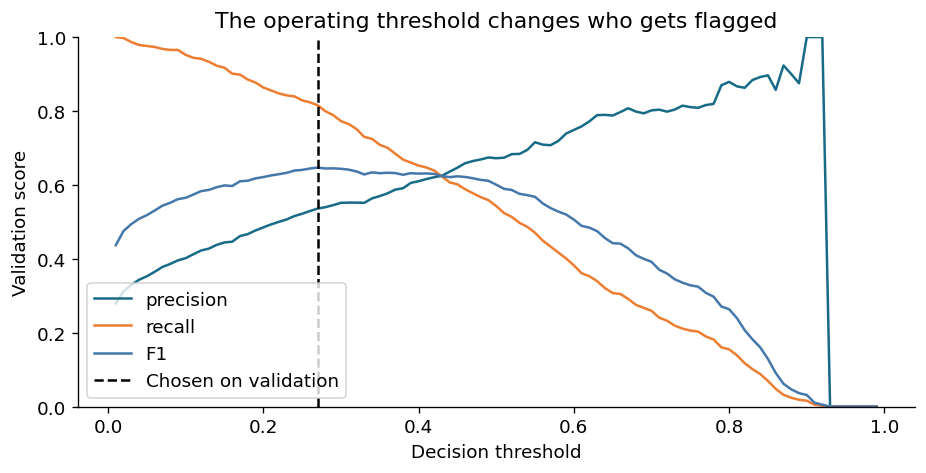

In [6]:
thresholds = threshold_table(y_valid, valid_probabilities[winner])
thresholds.to_csv(REPORTS / "validation_thresholds.csv", index=False)
choice = thresholds.sort_values(
    ["F1", "threshold"], ascending=[False, False]
).iloc[0]
threshold = float(choice.threshold)
print(f"Frozen model: {winner}; frozen threshold: {threshold:.2f}")
display(choice)
threshold_plot(thresholds, threshold, FIGURES)
plt.show()


## 6. Evaluate the untouched test set once

The same held-out customers evaluate all algorithms. Displaying their
results is a benchmark, not a new selection round. The deployed model
remains the validation winner even if another model leads on test AP.
Brier score measures probability error (lower is better). Calibration
is inspected; probabilities are not guaranteed to be reliable for any
particular customer.

,AP,ROC_AUC,Brier,Accuracy,Precision,Recall,F1
model,,,,,,,
Random forest,0.6273,0.8305,0.1411,0.7857,0.6364,0.4492,0.5266
Gradient boosting,0.6227,0.8267,0.1432,0.7835,0.6131,0.5000,0.5508
Logistic regression,0.6223,0.8327,0.1414,0.7885,0.6195,0.5267,0.5694
PyTorch MLP,0.6193,0.8326,0.1415,0.7878,0.6289,0.4893,0.5504
RBF SVM,0.5957,0.7930,0.1514,0.7885,0.6557,0.4278,0.5178
Decision tree,0.5953,0.8143,0.1467,0.7835,0.5972,0.5668,0.5816
K-nearest neighbors,0.5733,0.8067,0.1538,0.7757,0.5792,0.5668,0.5730
Gaussian Naive Bayes,0.5631,0.7991,0.3756,0.6132,0.3988,0.9011,0.5529
Prior baseline,0.2654,0.5000,0.1950,0.7346,0.0000,0.0000,0.0000


,threshold,AP,ROC_AUC,Brier,Accuracy,Precision,Recall,F1
0,0.5000,0.6227,0.8267,0.1432,0.7835,0.6131,0.5000,0.5508
1,0.2700,0.6227,0.8267,0.1432,0.7466,0.5150,0.7807,0.6206


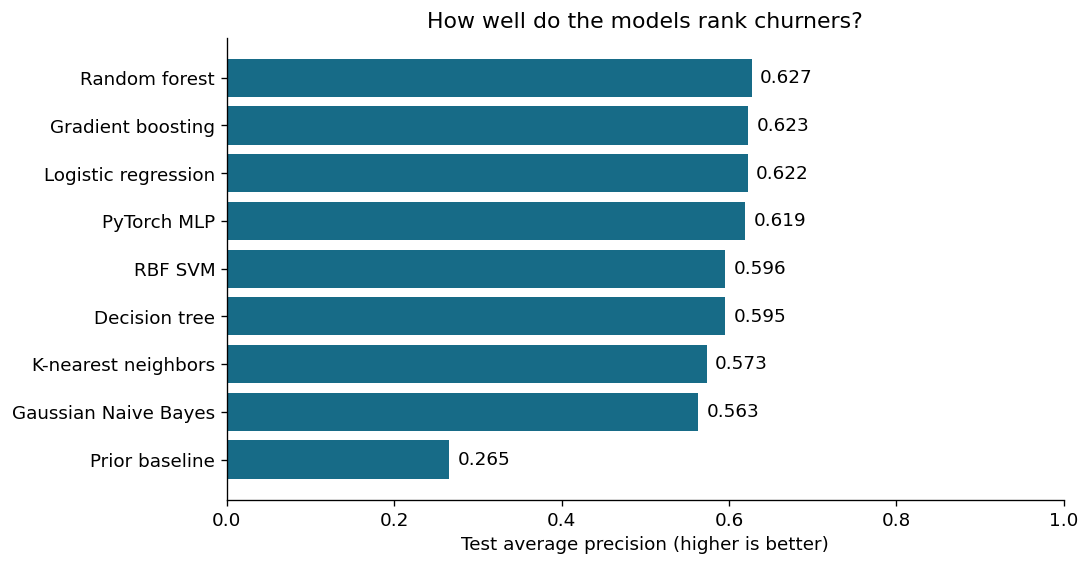

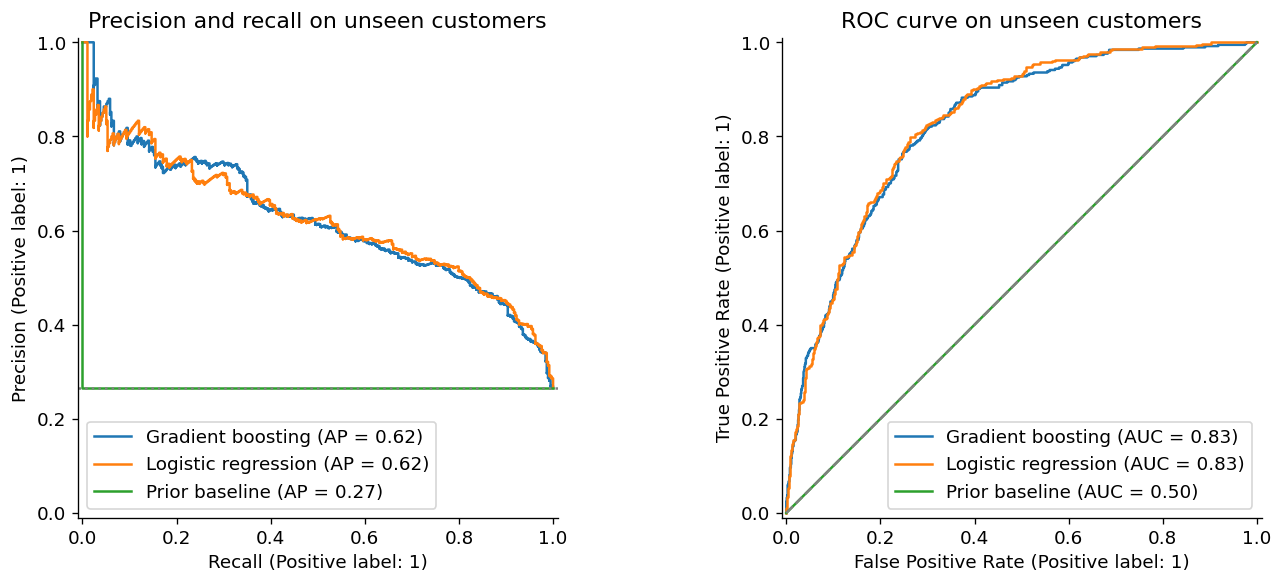

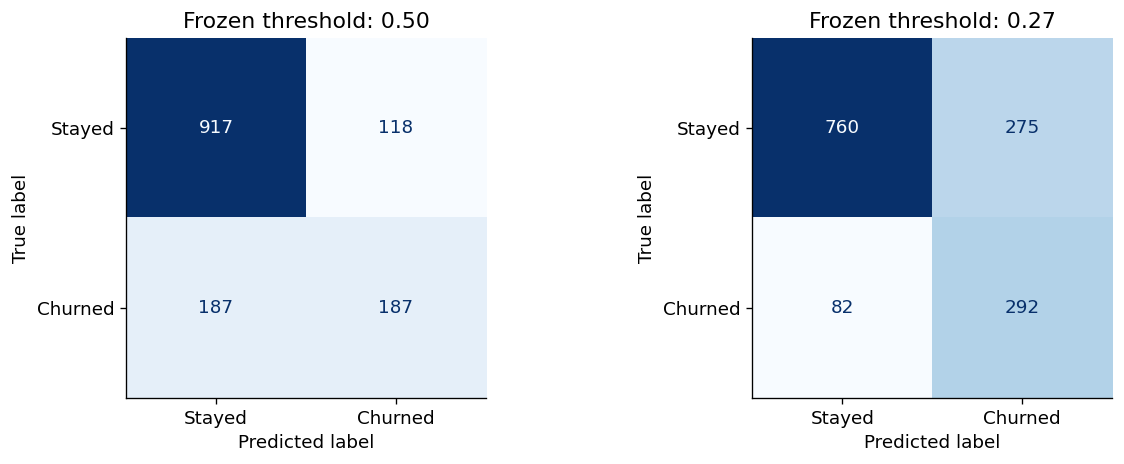

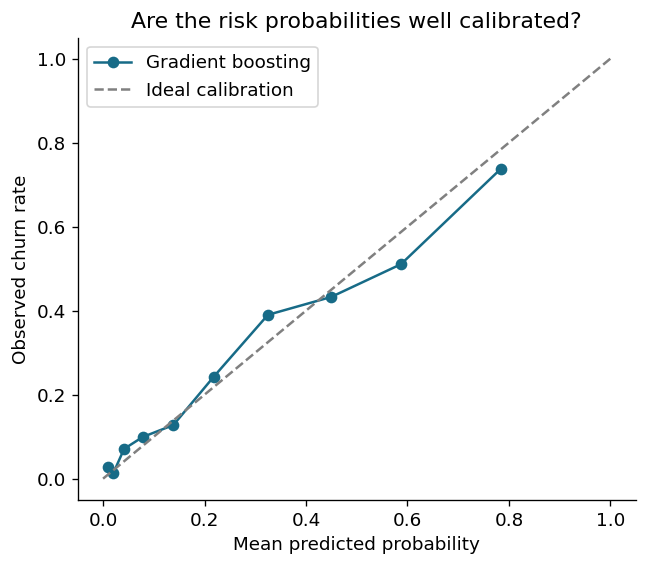

In [7]:
test_probabilities, test_rows = {}, []
for name, model in fitted.items():
    probability = model.predict_proba(x_test)[:, 1]
    test_probabilities[name] = probability
    test_rows.append({"model": name, **scores(y_test, probability)})
test_metrics = pd.DataFrame(test_rows).set_index("model")
test_metrics.to_csv(REPORTS / "test_metrics.csv")
selected_scores = scores(y_test, test_probabilities[winner], threshold)
operating = pd.DataFrame(
    [
        {"threshold": 0.5, **scores(y_test, test_probabilities[winner])},
        {"threshold": threshold, **selected_scores},
    ]
)
operating.to_csv(REPORTS / "selected_operating_points.csv", index=False)
predictions = test[["customerID", "Churn"]].copy()
for name, probability in test_probabilities.items():
    predictions[name] = probability
predictions["flagged"] = test_probabilities[winner] >= threshold
predictions.to_csv(REPORTS / "test_predictions.csv", index=False)
display(test_metrics.sort_values("AP", ascending=False))
display(operating)
comparison_plot(test_metrics, FIGURES)
diagnostic_plots(y_test, test_probabilities, winner, threshold, FIGURES)
plt.show()


## 7. Test the hypotheses with paired bootstrap intervals

Resample test customers 1,000 times. Each comparison uses the same sampled
customers for both methods. Intervals are conditional on these fitted
models and this split; they omit training, model-selection, and population
shift uncertainty. These are exploratory comparisons, without a
multiple-testing correction. An interval crossing zero is inconclusive.

In [8]:
first = test_probabilities["Gradient boosting"]
second = test_probabilities["Logistic regression"]
h1 = average_precision_score(y_test, first)
h1 -= average_precision_score(y_test, second)
h1_interval = bootstrap_difference(
    y_test, first, second, average_precision_score
)
p = test_probabilities[winner]
tuned, default = (p >= threshold).astype(int), (p >= 0.5).astype(int)
f1_metric = lambda y, prediction: f1_score(y, prediction, zero_division=0)
h2 = f1_metric(y_test, tuned) - f1_metric(y_test, default)
h2_interval = bootstrap_difference(y_test, tuned, default, f1_metric)
hypotheses = pd.DataFrame(
    [
        {
            "comparison": "Gradient boosting minus logistic AP",
            "difference": h1,
            "lower": h1_interval[0],
            "upper": h1_interval[1],
        },
        {
            "comparison": "Tuned minus default threshold F1",
            "difference": h2,
            "lower": h2_interval[0],
            "upper": h2_interval[1],
        },
    ]
)
hypotheses["conclusion"] = hypotheses.apply(
    lambda row: (
        "Positive difference supported"
        if row.lower > 0
        else (
            "Negative difference supported"
            if row.upper < 0
            else "Inconclusive"
        )
    ),
    axis=1,
)
hypotheses.to_csv(REPORTS / "hypotheses.csv", index=False)
display(hypotheses)


,comparison,difference,lower,upper,conclusion
0,Gradient boosting minus logistic AP,0.0003,-0.0223,0.0245,Inconclusive
1,Tuned minus default threshold F1,0.0698,0.0340,0.1084,Positive difference supported


## 8. Engineering the 3D evidence

**Observed customer cohorts:** training customers are grouped by tenure
and monthly charges. Marker size reflects sample size; vertical bars are
95% Wilson intervals. Groups with fewer than 20 customers are omitted.
This tests whether high-charge, short-tenure cohorts have higher observed
churn, without creating inconsistent synthetic billing histories. These
are associations and may reflect differences in contract or services.

**Decision-cost surface:** z = 100 × (FP + ratio × FN) / validation N.
One false alarm costs one hypothetical unit; a missed churner costs
1–10 units. Changing these assumptions changes the preferred threshold.
The dataset cannot estimate saved customers, treatment effects, or ROI.
A high churn score does not establish that an offer would prevent churn.

In [9]:
cohort_figure = cohort_plot(train, FIGURES)
cost_figure = cost_plot(thresholds, len(validation), FIGURES)
display(cohort_figure)
display(cost_figure)
plt.close("all")


## 9. Explain behavior and inspect limitations

Permutation importance shuffles one raw input column at a time on
validation data. Correlated billing and service columns can share or mask
importance. Shuffling can form unrealistic combinations, so this is a
predictive sensitivity diagnostic, not a causal explanation.

Subgroup errors below are descriptive and can be noisy. They do not
certify fairness. Protected attributes and proxies require a separate
review before any operational use. No automated action is taken.

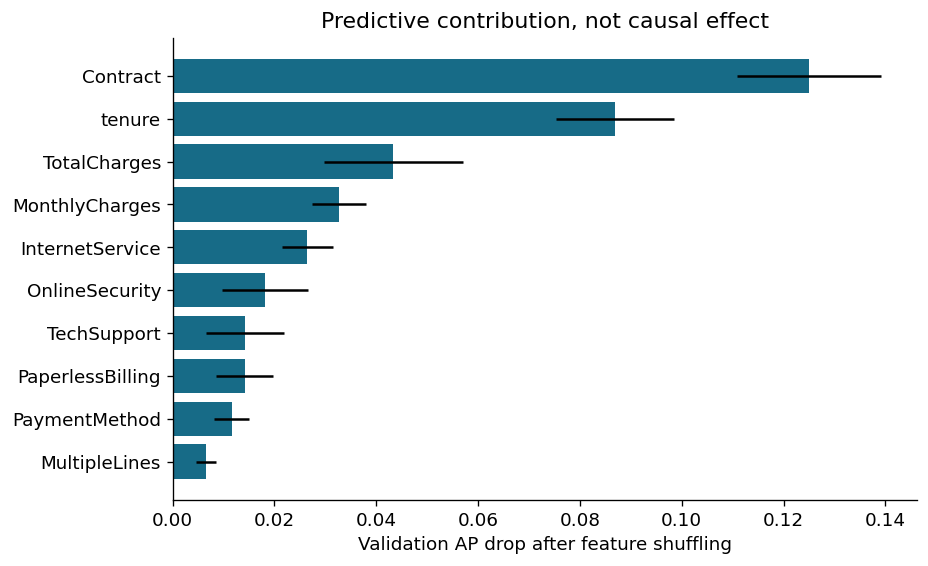

,attribute,group,n,AP,ROC_AUC,Brier,Accuracy,Precision,Recall,F1
0,gender,Female,714,0.6185,0.8182,0.1550,0.7465,0.5448,0.7633,0.6358
1,gender,Male,695,0.6353,0.8375,0.1312,0.7468,0.4838,0.8024,0.6036
2,SeniorCitizen,0,1170,0.6057,0.8343,0.1301,0.7667,0.4988,0.7574,0.6015
3,SeniorCitizen,1,239,0.6645,0.7410,0.2075,0.6485,0.5584,0.8431,0.6719
4,Contract,Month-to-month,786,0.6587,0.7416,0.2018,0.6260,0.5275,0.8889,0.6621
5,Contract,One year,284,0.2616,0.7485,0.1035,0.8380,0.2222,0.1111,0.1481
6,Contract,Two year,339,0.0769,0.6503,0.0408,0.9499,0.0000,0.0000,0.0000


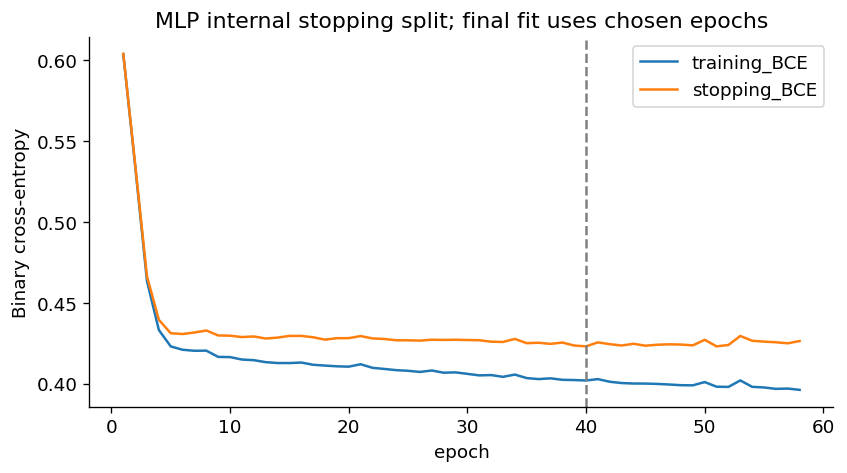

In [10]:
result = permutation_importance(
    selected,
    x_valid,
    y_valid,
    scoring="average_precision",
    n_repeats=5,
    random_state=SEED,
    n_jobs=1,
)
importance = pd.DataFrame(
    {
        "feature": FEATURES,
        "mean": result.importances_mean,
        "std": result.importances_std,
    }
).sort_values("mean", ascending=False)
importance.to_csv(REPORTS / "permutation_importance.csv", index=False)
importance_plot(importance, FIGURES)
plt.show()
subgroup_rows = []
for column in ["gender", "SeniorCitizen", "Contract"]:
    for value in sorted(test[column].unique()):
        mask = test[column].eq(value).to_numpy()
        if mask.sum() < 30 or y_test.to_numpy()[mask].sum() < 5:
            continue
        subgroup_rows.append(
            {
                "attribute": column,
                "group": value,
                "n": int(mask.sum()),
                **scores(y_test.to_numpy()[mask], p[mask], threshold),
            }
        )
subgroups = pd.DataFrame(subgroup_rows)
subgroups.to_csv(REPORTS / "subgroup_metrics.csv", index=False)
display(subgroups)
history = pd.DataFrame(
    fitted["PyTorch MLP"].history_,
    columns=["epoch", "training_BCE", "stopping_BCE"],
)
history.to_csv(REPORTS / "neural_training_history.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4))
history.plot(x="epoch", y=["training_BCE", "stopping_BCE"], ax=ax)
ax.axvline(fitted["PyTorch MLP"].best_epoch_, linestyle="--", color="grey")
ax.set_title("MLP internal stopping split; final fit uses chosen epochs")
ax.set_ylabel("Binary cross-entropy")
save_figure(fig, FIGURES, "neural_learning_curve")
plt.show()


## 10. Package the fitted model and findings

The saved bundle contains the fitted preprocessing, model, frozen
threshold, input categories, and training bounds. The Streamlit app uses
that exact fit; it does not retrain on launch. CSV uploads are processed
in memory and are not written to disk by the app.

In [11]:
bundle = {
    "name": winner,
    "model": selected,
    "threshold": threshold,
    "features": FEATURES,
    "test_scores": selected_scores,
    "example": train[FEATURES].iloc[0].to_dict(),
    "bounds": {
        col: (float(train[col].min()), float(train[col].max()))
        for col in NUMERIC
    },
    "categories": {
        col: sorted(train[col].dropna().unique().tolist())
        for col in CATEGORICAL
    },
}
joblib.dump(bundle, ROOT / "models/churn_model.joblib", compress=3)
joblib.dump(fitted, ROOT / "models/all_models.joblib", compress=3)
summary = {
    "audit": audit,
    "selected_model": winner,
    "threshold": threshold,
    "test_scores": selected_scores,
    "split_sizes": {name: len(part) for name, part in parts.items()},
    "mlp_best_epoch": int(fitted["PyTorch MLP"].best_epoch_),
    "selection_metric": "Validation average precision",
    "hypotheses": hypotheses.to_dict(orient="records"),
}
(REPORTS / "run_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)
lines = [
    "# Measured findings",
    "",
    f"Selected model: **{winner}**, using validation average precision.",
    f"Frozen validation-F1 threshold: **{threshold:.2f}**.",
    "",
    "## Held-out customers",
    "",
    f"Test customers: {len(test):,}.",
]
for metric, value in selected_scores.items():
    lines.append(f"- {metric}: {value:.4f}")
lines.extend(["", "## Hypotheses", ""])
for row in hypotheses.itertuples():
    lines.append(
        f"- {row.comparison}: {row.difference:.4f}; "
        f"95% paired bootstrap interval "
        f"[{row.lower:.4f}, {row.upper:.4f}]. {row.conclusion}."
    )
lines.extend(
    [
        "",
        "## What this supports",
        "",
        "The comparison measures retrospective classification on a random",
        (
            "customer holdout. Model selection and thresholds used "
            "validation only."
        ),
        (
            "The test table uses 0.50 for all models; the selected "
            "operating-point"
        ),
        "table also reports the frozen validation threshold.",
        "",
        "## Limits",
        "",
        (
            "No timestamp or future observation window is available. "
            "These results"
        ),
        "do not establish future churn accuracy, causal retention effects,",
        "individual certainty, or financial return. Cohort error bars and",
        (
            "bootstrap intervals do not include population or "
            "training uncertainty."
        ),
        (
            "F1 is an educational choice; actual outreach requires "
            "cost and capacity"
        ),
        (
            "data and a separately evaluated policy. Subgroup "
            "metrics are descriptive."
        ),
    ]
)
(REPORTS / "findings.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("Saved fitted pipeline, findings, predictions, and plots.")
display(pd.Series(selected_scores, name=winner))


Saved fitted pipeline, findings, predictions, and plots.


AP          0.6227
ROC_AUC     0.8267
Brier       0.1432
Accuracy    0.7466
Precision   0.5150
Recall      0.7807
F1          0.6206
Name: Gradient boosting, dtype: float64

## References and next experiments

- [IBM Telco sample project](https://github.com/IBM/telco-customer-churn-on-icp4d)
- [Kaggle distribution](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- [Scikit-learn threshold selection](https://scikit-learn.org/stable/modules/classification_threshold.html)
- [Scikit-learn average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)

A future study could use dated customer snapshots with a clear forecast
window, out-of-time testing, training-only calibration, and a randomized
retention experiment. Those require new data and a fresh evaluation set;
this test set should not become a tuning set.